# 05 · Comparing recordings under identical baselines

Each recording becomes one whole-FOV ΔF/F per baseline definition. In multi-plane recordings, ΔF/F is computed per plane and then averaged across planes. The definitions are set in seconds and percentiles, so they mean the same thing at 30 Hz (corridor2) and at about 7.5 Hz per plane (4-plane recordings).

Read the bottom-row panels first. If the lines keep their order across baseline methods, the difference between recordings doesn't depend on the baseline. If they cross, it does. Absolute ΔF/F across different fields of view, depths, zooms or laser powers is not directly comparable, so treat corridor2 vs passive as qualitative. Run `00_extract_traces` first for the corridor2 recordings.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from nlight import plotting, recording_comparison, session, workflows

plotting.use_lab_style()
RECORDINGS = session.load_recordings(Path('../../configs/nlight_recordings.json'))
print('Available:', list(RECORDINGS))

Available: ['corridor2 passive viewing', 'corridor2 baseline', 'passive (4 planes)', 'no puff (2x, 4 planes)', 'puff (2x, 4 planes)']


In [2]:
SPEC = recording_comparison.BaselineSpec(current_window_s=60, current_percentile=50,
                                         fixed_percentiles=(10,), long_windows_s=(180, 300, 600))
SLOW_TIMESCALE_S = 10

def compare(names, title):
    summaries, table = workflows.compare_recordings(
        {n: RECORDINGS[n].export_root for n in names}, SPEC, SLOW_TIMESCALE_S)
    fig = plotting.recording_comparison_figure(summaries, table, title=title)
    display(fig); plt.close(fig)
    display(table[['median_dff_pct', 'p5_to_p95_pp', 'slow_p5_to_p95_pp', 'fast_std_pp', 'raw_drift_pct']].round(2))
    if len(names) == 2:
        display(recording_comparison.paired_difference(table, *names).round(2))
    return summaries, table

## Airpuff: no puff vs puff (2x, 4 planes each)

/Users/megyoung/mini2p-preprocessing/src/nlight/baseline_comparison.py:44: UserWarning: skipping 300 s window: recording is 221 s
  warnings.warn(f"skipping {seconds:g} s window: recording is {duration_s:.0f} s")
/Users/megyoung/mini2p-preprocessing/src/nlight/baseline_comparison.py:44: UserWarning: skipping 600 s window: recording is 221 s
  warnings.warn(f"skipping {seconds:g} s window: recording is {duration_s:.0f} s")
/Users/megyoung/mini2p-preprocessing/src/nlight/baseline_comparison.py:44: UserWarning: skipping 300 s window: recording is 221 s
  warnings.warn(f"skipping {seconds:g} s window: recording is {duration_s:.0f} s")
/Users/megyoung/mini2p-preprocessing/src/nlight/baseline_comparison.py:44: UserWarning: skipping 600 s window: recording is 221 s
  warnings.warn(f"skipping {seconds:g} s window: recording is {duration_s:.0f} s")
/Users/megyoung/mini2p-preprocessing/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW

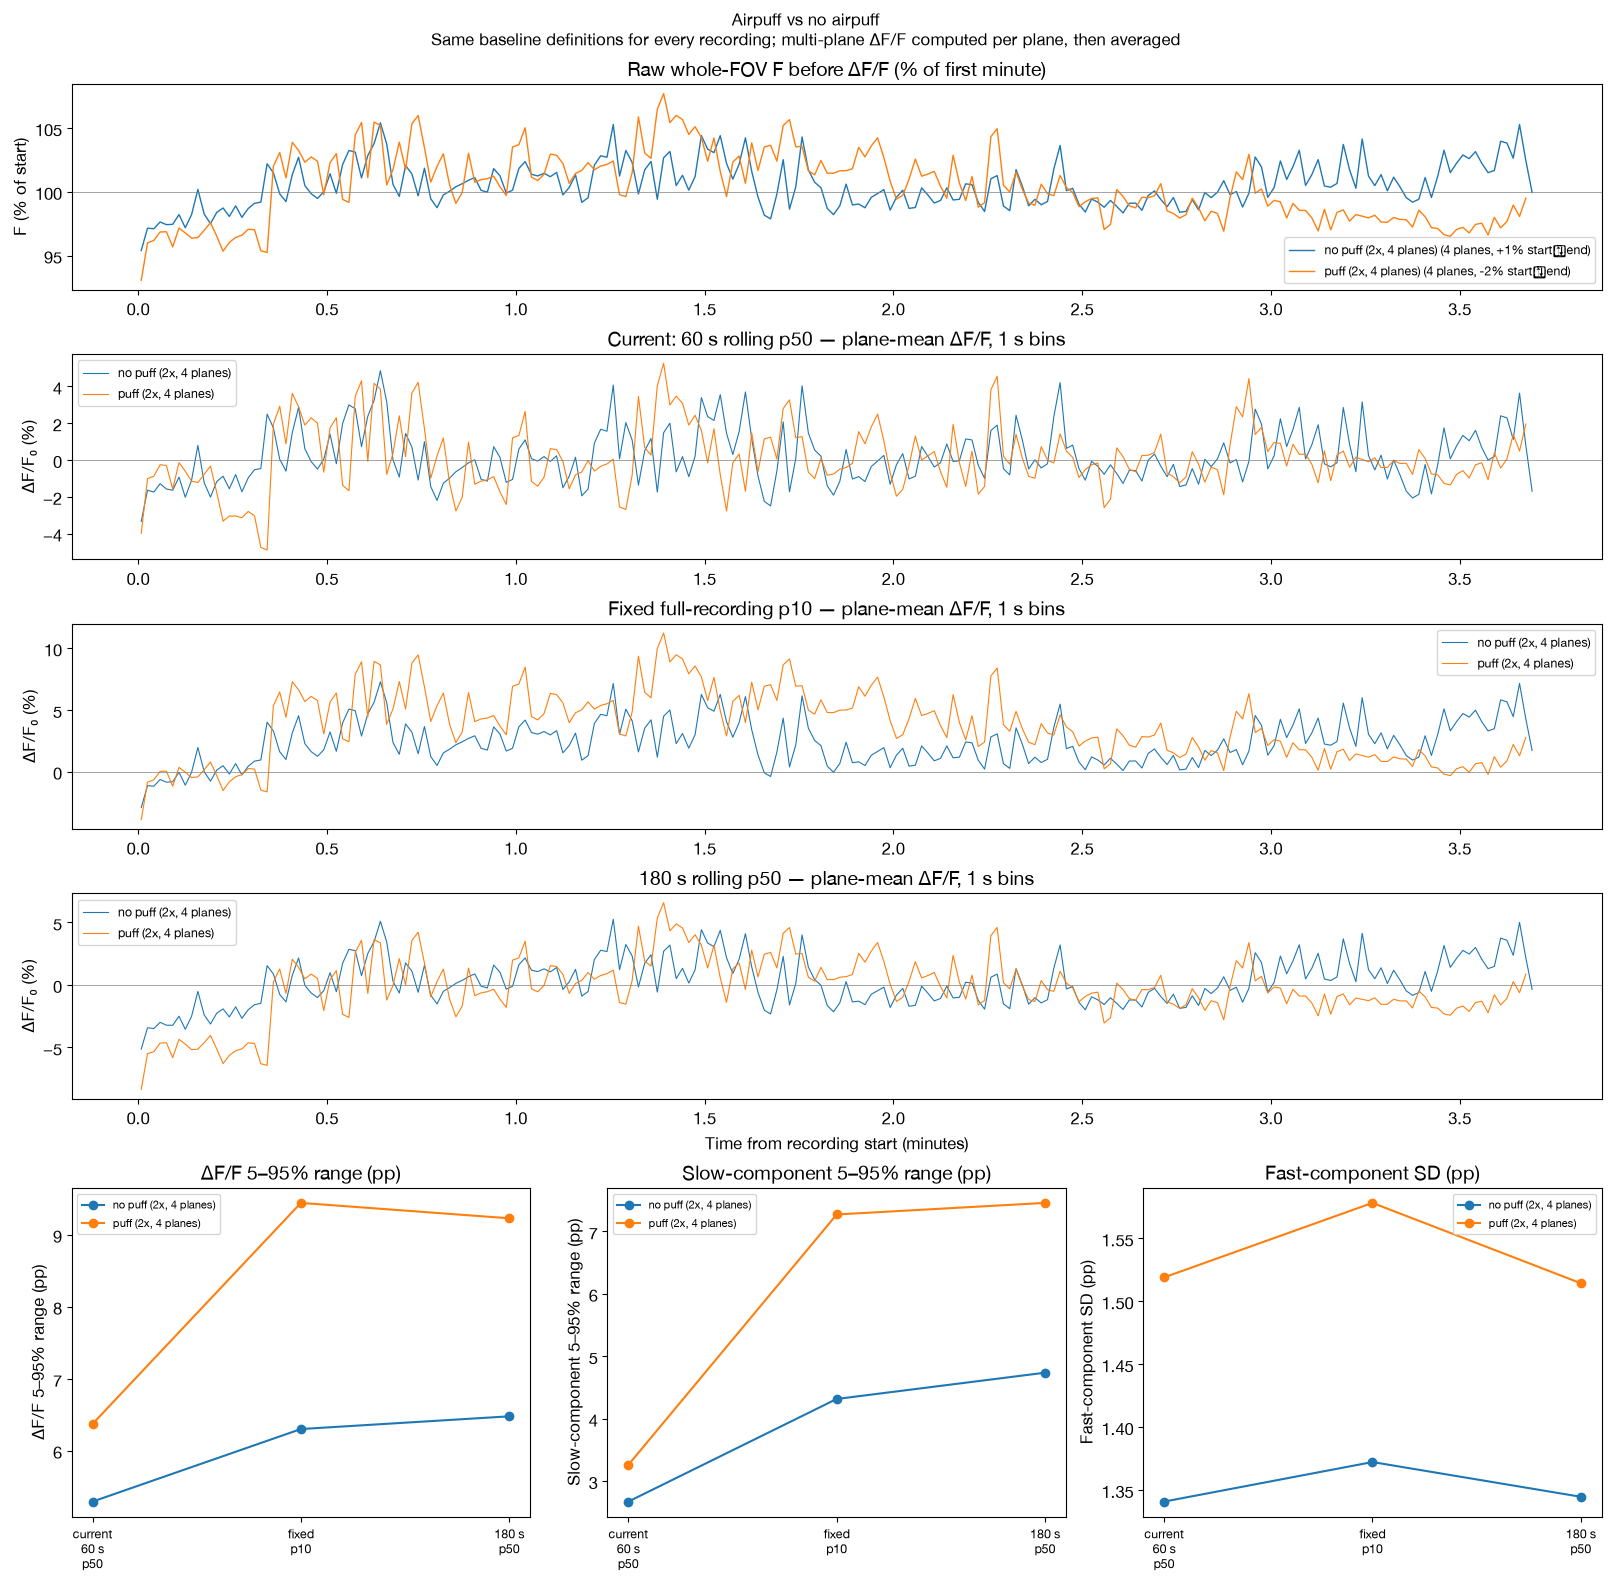

median_dff_pct  \
recording              method                                      
no puff (2x, 4 planes) Current: 60 s rolling p50           -0.05   
                       Fixed full-recording p10             2.05   
                       180 s rolling p50                    0.02   
puff (2x, 4 planes)    Current: 60 s rolling p50           -0.13   
                       Fixed full-recording p10             3.57   
                       180 s rolling p50                   -0.30   

                                                  p5_to_p95_pp  \
recording              method                                    
no puff (2x, 4 planes) Current: 60 s rolling p50          5.29   
                       Fixed full-recording p10           6.30   
                       180 s rolling p50                  6.48   
puff (2x, 4 planes)    Current: 60 s rolling p50          6.37   
                       Fixed full-recording p10           9.44   
                       180 s rolling p50                  9.23   

                                                  slow_p5_to_p95_pp  \
recording              method                                         
no puff (2x, 4 planes) Current: 60 s rolling p50               2.67   
                       Fixed full-recording p10                4.31   
                       180 s rolling p50                       4.74   
puff (2x, 4 planes)    Current: 60 s rolling p50               3.26   
                       Fixed full-recording p10                7.27   
                       180 s rolling p50                       7.45   

                                                  fast_std_pp  raw_drift_pct  
recording              method                                                 
no puff (2x, 4 planes) Current: 60 s rolling p50         1.34           1.24  
                       Fixed full-recording p10          1.37           1.24  
                       180 s rolling p50                 1.34           1.24  
puff (2x, 4 planes)    Current: 60 s rolling p50         1.52          -1.74  
                       Fixed full-recording p10          1.58          -1.74  
                       180 s rolling p50                 1.51          -1.74

no puff (2x, 4 planes) − puff (2x, 4 planes)  \
                                                        median_dff_pct   
method                                                                   
Current: 60 s rolling p50                                         0.08   
Fixed full-recording p10                                         -1.51   
180 s rolling p50                                                 0.32   

                                                                      \
                          p5_to_p95_pp slow_p5_to_p95_pp fast_std_pp   
method                                                                 
Current: 60 s rolling p50        -1.08             -0.59       -0.18   
Fixed full-recording p10         -3.14             -2.95       -0.21   
180 s rolling p50                -2.75             -2.72       -0.17   

                          no puff (2x, 4 planes) / puff (2x, 4 planes)  \
                                                        median_dff_pct   
method                                                                   
Current: 60 s rolling p50                                         0.42   
Fixed full-recording p10                                          0.58   
180 s rolling p50                                                -0.07   

                                                                      
                          p5_to_p95_pp slow_p5_to_p95_pp fast_std_pp  
method                                                                
Current: 60 s rolling p50         0.83              0.82        0.88  
Fixed full-recording p10          0.67              0.59        0.87  
180 s rolling p50                 0.70              0.64        0.89

In [3]:
airpuff = compare(['no puff (2x, 4 planes)', 'puff (2x, 4 planes)'], 'Airpuff vs no airpuff')

## corridor2: passive viewing vs pre-corridor baseline

/Users/megyoung/mini2p-preprocessing/src/nlight/baseline_comparison.py:44: UserWarning: skipping 600 s window: recording is 563 s
  warnings.warn(f"skipping {seconds:g} s window: recording is {duration_s:.0f} s")
/Users/megyoung/mini2p-preprocessing/src/nlight/baseline_comparison.py:44: UserWarning: skipping 600 s window: recording is 463 s
  warnings.warn(f"skipping {seconds:g} s window: recording is {duration_s:.0f} s")
/Users/megyoung/mini2p-preprocessing/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Neue.
  fig.canvas.print_figure(bytes_io, **kw)


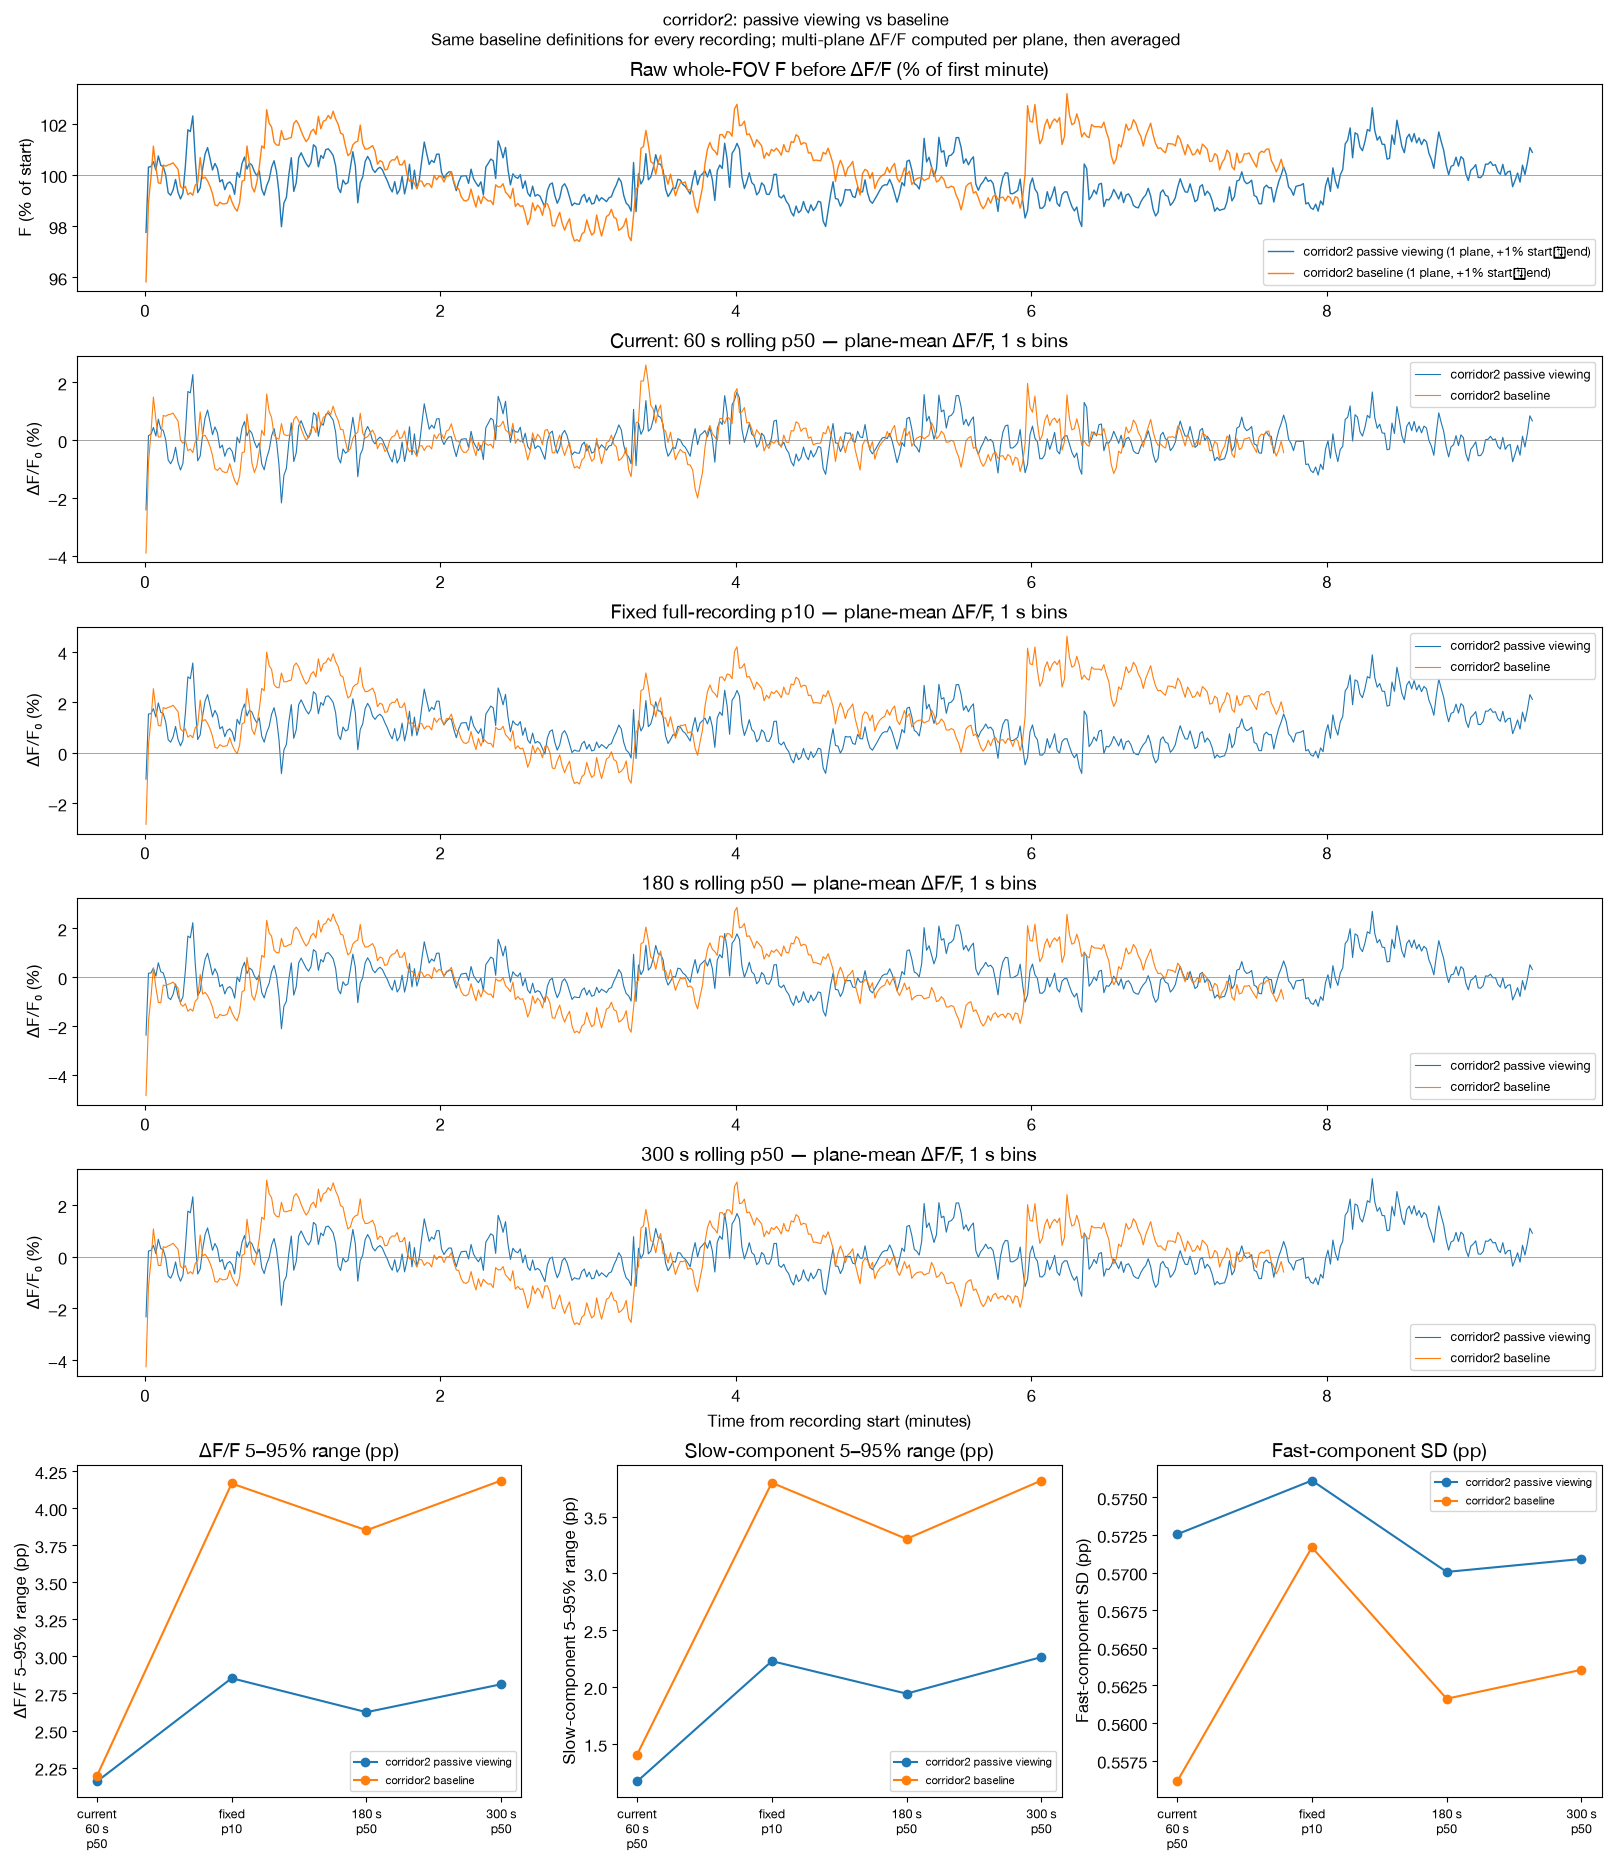

median_dff_pct  \
recording                 method                                      
corridor2 passive viewing Current: 60 s rolling p50            0.00   
                          Fixed full-recording p10             0.94   
                          180 s rolling p50                    0.01   
                          300 s rolling p50                    0.04   
corridor2 baseline        Current: 60 s rolling p50           -0.00   
                          Fixed full-recording p10             1.71   
                          180 s rolling p50                   -0.08   
                          300 s rolling p50                    0.06   

                                                     p5_to_p95_pp  \
recording                 method                                    
corridor2 passive viewing Current: 60 s rolling p50          2.16   
                          Fixed full-recording p10           2.85   
                          180 s rolling p50                  2.62   
                          300 s rolling p50                  2.81   
corridor2 baseline        Current: 60 s rolling p50          2.19   
                          Fixed full-recording p10           4.17   
                          180 s rolling p50                  3.85   
                          300 s rolling p50                  4.19   

                                                     slow_p5_to_p95_pp  \
recording                 method                                         
corridor2 passive viewing Current: 60 s rolling p50               1.17   
                          Fixed full-recording p10                2.23   
                          180 s rolling p50                       1.94   
                          300 s rolling p50                       2.26   
corridor2 baseline        Current: 60 s rolling p50               1.40   
                          Fixed full-recording p10                3.80   
                          180 s rolling p50                       3.30   
                          300 s rolling p50                       3.82   

                                                     fast_std_pp  \
recording                 method                                   
corridor2 passive viewing Current: 60 s rolling p50         0.57   
                          Fixed full-recording p10          0.58   
                          180 s rolling p50                 0.57   
                          300 s rolling p50                 0.57   
corridor2 baseline        Current: 60 s rolling p50         0.56   
                          Fixed full-recording p10          0.57   
                          180 s rolling p50                 0.56   
                          300 s rolling p50                 0.56   

                                                     raw_drift_pct  
recording                 method                                    
corridor2 passive viewing Current: 60 s rolling p50           0.64  
                          Fixed full-recording p10            0.64  
                          180 s rolling p50                   0.64  
                          300 s rolling p50                   0.64  
corridor2 baseline        Current: 60 s rolling p50           0.91  
                          Fixed full-recording p10            0.91  
                          180 s rolling p50                   0.91  
                          300 s rolling p50                   0.91

corridor2 passive viewing − corridor2 baseline  \
                                                          median_dff_pct   
method                                                                     
Current: 60 s rolling p50                                           0.00   
Fixed full-recording p10                                           -0.77   
180 s rolling p50                                                   0.09   
300 s rolling p50                                                  -0.02   

                                                                      \
                          p5_to_p95_pp slow_p5_to_p95_pp fast_std_pp   
method                                                                 
Current: 60 s rolling p50        -0.04             -0.24        0.02   
Fixed full-recording p10         -1.31             -1.57        0.00   
180 s rolling p50                -1.23             -1.36        0.01   
300 s rolling p50                -1.37             -1.55        0.01   

                          corridor2 passive viewing / corridor2 baseline  \
                                                          median_dff_pct   
method                                                                     
Current: 60 s rolling p50                                          -0.02   
Fixed full-recording p10                                            0.55   
180 s rolling p50                                                  -0.07   
300 s rolling p50                                                   0.62   

                                                                      
                          p5_to_p95_pp slow_p5_to_p95_pp fast_std_pp  
method                                                                
Current: 60 s rolling p50         0.98              0.83        1.03  
Fixed full-recording p10          0.68              0.59        1.01  
180 s rolling p50                 0.68              0.59        1.02  
300 s rolling p50                 0.67              0.59        1.01

In [4]:
corridor2 = compare(['corridor2 passive viewing', 'corridor2 baseline'], 'corridor2: passive viewing vs baseline')

## corridor2 (1 plane) vs passive (mean of 4 planes)

/Users/megyoung/mini2p-preprocessing/src/nlight/baseline_comparison.py:44: UserWarning: skipping 600 s window: recording is 563 s
  warnings.warn(f"skipping {seconds:g} s window: recording is {duration_s:.0f} s")
/Users/megyoung/mini2p-preprocessing/src/nlight/baseline_comparison.py:44: UserWarning: skipping 600 s window: recording is 392 s
  warnings.warn(f"skipping {seconds:g} s window: recording is {duration_s:.0f} s")
/Users/megyoung/mini2p-preprocessing/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Neue.
  fig.canvas.print_figure(bytes_io, **kw)


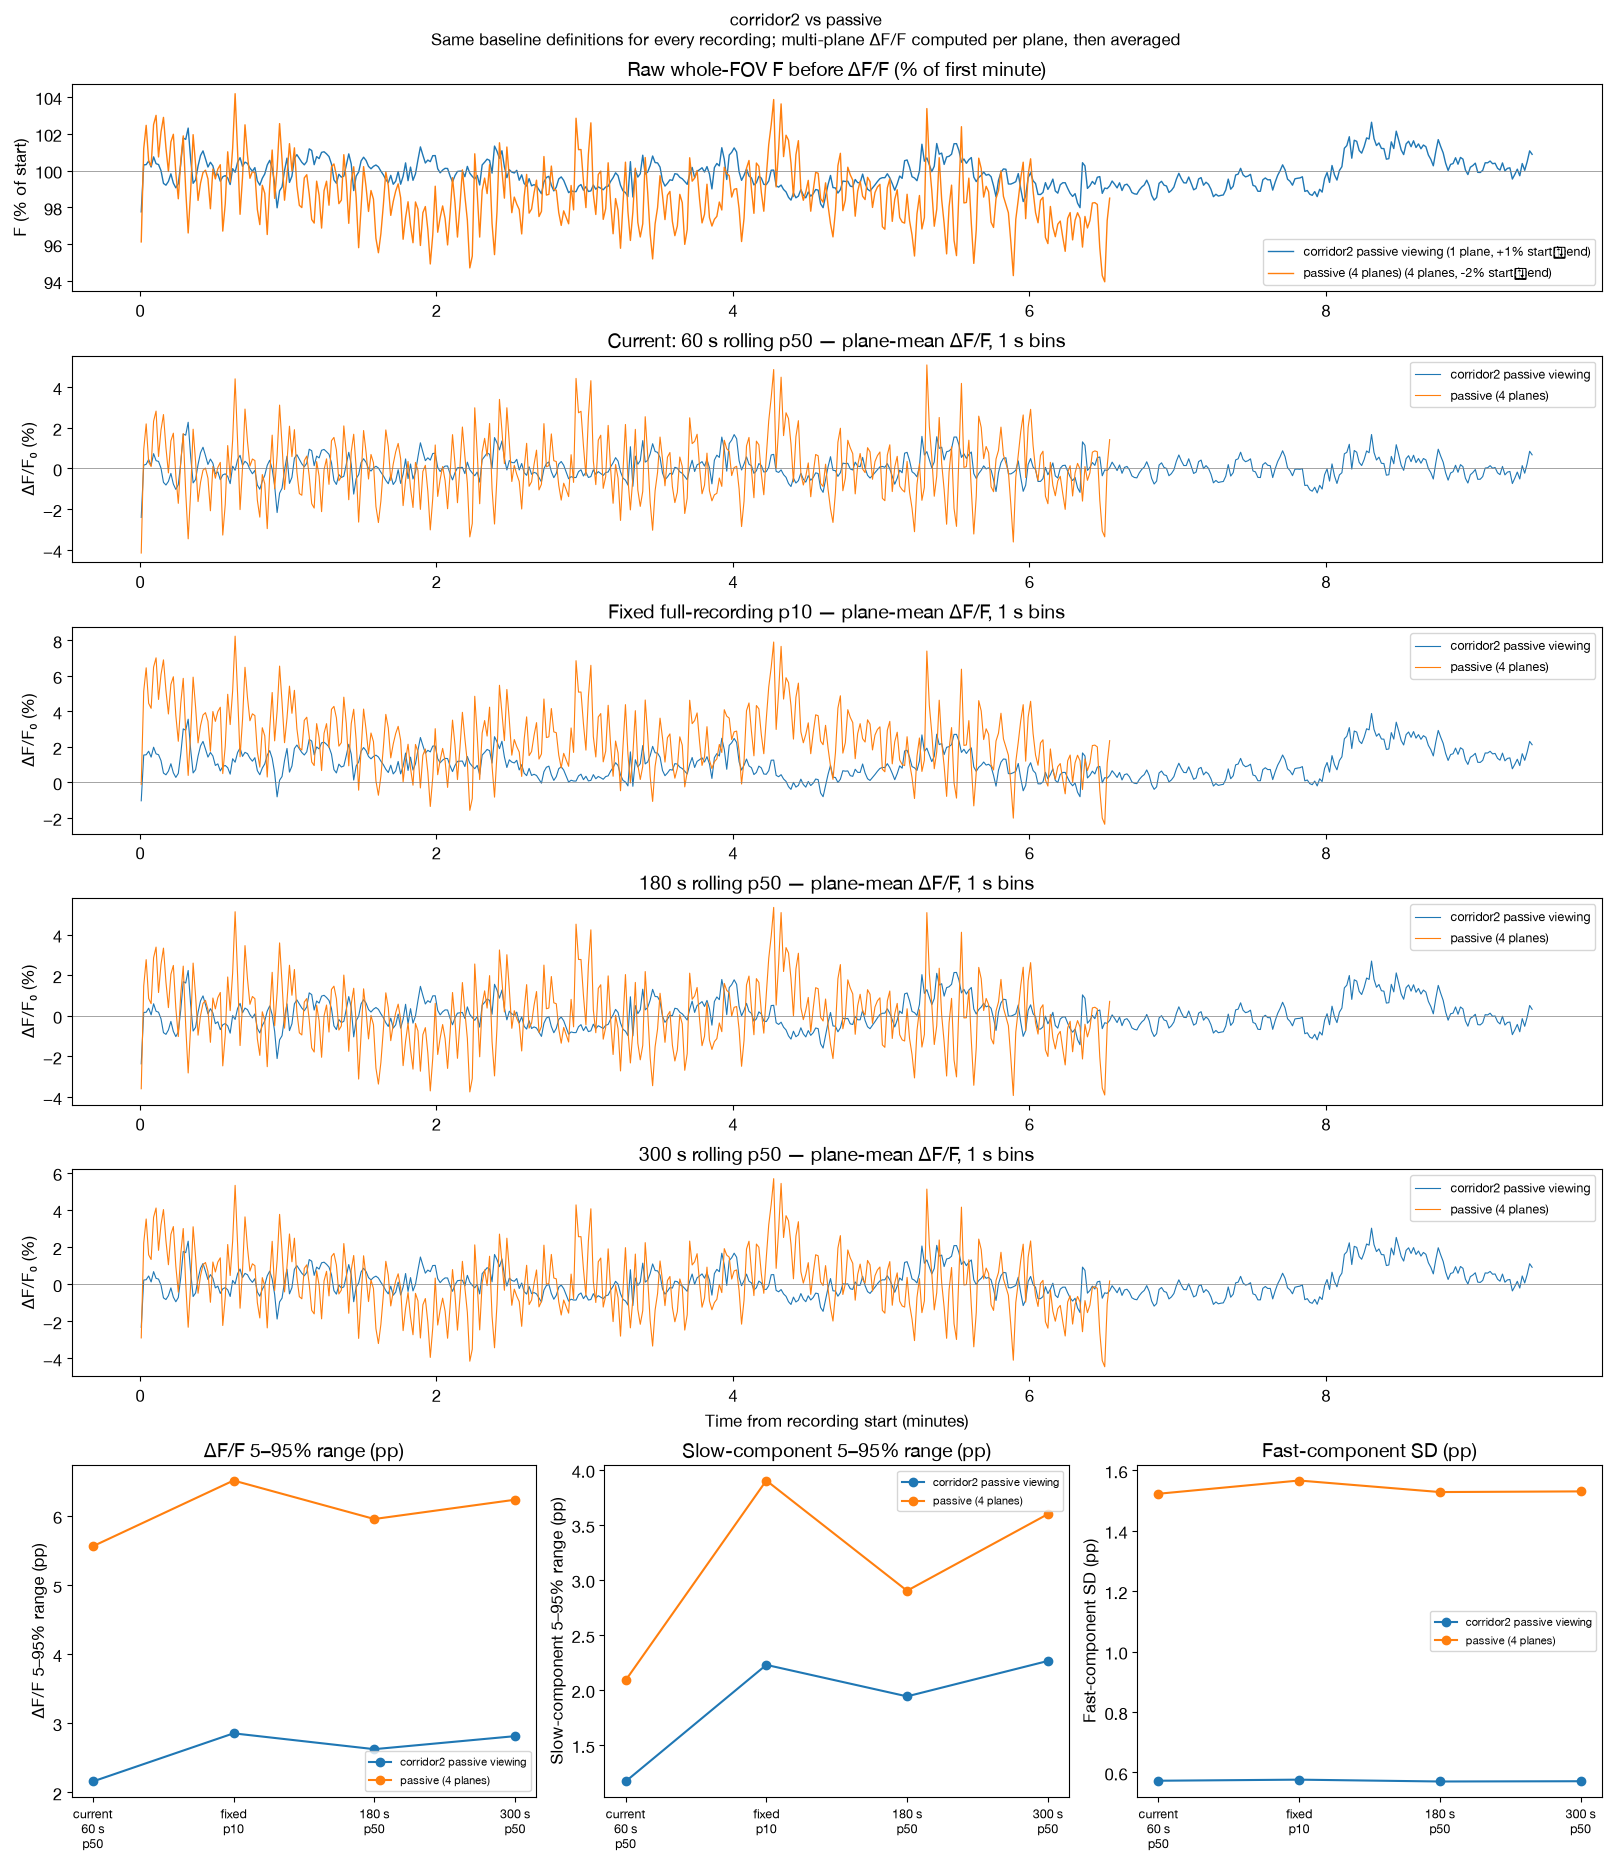

median_dff_pct  \
recording                 method                                      
corridor2 passive viewing Current: 60 s rolling p50            0.00   
                          Fixed full-recording p10             0.94   
                          180 s rolling p50                    0.01   
                          300 s rolling p50                    0.04   
passive (4 planes)        Current: 60 s rolling p50            0.01   
                          Fixed full-recording p10             2.37   
                          180 s rolling p50                    0.03   
                          300 s rolling p50                    0.01   

                                                     p5_to_p95_pp  \
recording                 method                                    
corridor2 passive viewing Current: 60 s rolling p50          2.16   
                          Fixed full-recording p10           2.85   
                          180 s rolling p50                  2.62   
                          300 s rolling p50                  2.81   
passive (4 planes)        Current: 60 s rolling p50          5.56   
                          Fixed full-recording p10           6.51   
                          180 s rolling p50                  5.95   
                          300 s rolling p50                  6.23   

                                                     slow_p5_to_p95_pp  \
recording                 method                                         
corridor2 passive viewing Current: 60 s rolling p50               1.17   
                          Fixed full-recording p10                2.23   
                          180 s rolling p50                       1.94   
                          300 s rolling p50                       2.26   
passive (4 planes)        Current: 60 s rolling p50               2.09   
                          Fixed full-recording p10                3.90   
                          180 s rolling p50                       2.90   
                          300 s rolling p50                       3.60   

                                                     fast_std_pp  \
recording                 method                                   
corridor2 passive viewing Current: 60 s rolling p50         0.57   
                          Fixed full-recording p10          0.58   
                          180 s rolling p50                 0.57   
                          300 s rolling p50                 0.57   
passive (4 planes)        Current: 60 s rolling p50         1.52   
                          Fixed full-recording p10          1.57   
                          180 s rolling p50                 1.53   
                          300 s rolling p50                 1.53   

                                                     raw_drift_pct  
recording                 method                                    
corridor2 passive viewing Current: 60 s rolling p50           0.64  
                          Fixed full-recording p10            0.64  
                          180 s rolling p50                   0.64  
                          300 s rolling p50                   0.64  
passive (4 planes)        Current: 60 s rolling p50          -2.31  
                          Fixed full-recording p10           -2.31  
                          180 s rolling p50                  -2.31  
                          300 s rolling p50                  -2.31

corridor2 passive viewing − passive (4 planes)  \
                                                          median_dff_pct   
method                                                                     
Current: 60 s rolling p50                                          -0.01   
Fixed full-recording p10                                           -1.43   
180 s rolling p50                                                  -0.02   
300 s rolling p50                                                   0.03   

                                                                      \
                          p5_to_p95_pp slow_p5_to_p95_pp fast_std_pp   
method                                                                 
Current: 60 s rolling p50        -3.40             -0.92       -0.95   
Fixed full-recording p10         -3.66             -1.67       -0.99   
180 s rolling p50                -3.33             -0.96       -0.96   
300 s rolling p50                -3.42             -1.33       -0.96   

                          corridor2 passive viewing / passive (4 planes)  \
                                                          median_dff_pct   
method                                                                     
Current: 60 s rolling p50                                           0.00   
Fixed full-recording p10                                            0.40   
180 s rolling p50                                                   0.20   
300 s rolling p50                                                   4.39   

                                                                      
                          p5_to_p95_pp slow_p5_to_p95_pp fast_std_pp  
method                                                                
Current: 60 s rolling p50         0.39              0.56        0.38  
Fixed full-recording p10          0.44              0.57        0.37  
180 s rolling p50                 0.44              0.67        0.37  
300 s rolling p50                 0.45              0.63        0.37

In [5]:
across = compare(['corridor2 passive viewing', 'passive (4 planes)'], 'corridor2 vs passive')